In [3]:
print("Customer Churn Analysis Project Started!")

Customer Churn Analysis Project Started!


In [4]:
print("Customer Churn Analysis Project Started!")
print("Python is working successfully!")

Customer Churn Analysis Project Started!
Python is working successfully!


In [5]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option('display.max_columns', None)

print("All libraries imported successfully!")

All libraries imported successfully!


In [6]:
# Load the dataset

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

# Display first 5 rows
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [7]:
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

Total Rows: 7043
Total Columns: 21


In [8]:
# Check data types of all columns

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [9]:
# Check missing values in each column

missing_values = df.isnull().sum()

print(missing_values)

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [10]:
print("Missing Values:")
print(df.isnull().sum().sum())

print("\nBlank TotalCharges:")
print((df['TotalCharges'].str.strip() == '').sum())

Missing Values:
0

Blank TotalCharges:
11


In [11]:
print("Duplicate Rows:", df.duplicated().sum())

print("Duplicate Customer IDs:",
      df['customerID'].duplicated().sum())

Duplicate Rows: 0
Duplicate Customer IDs: 0


In [12]:
print(df['Churn'].value_counts())

print("\nChurn Percentage:")
print(df['Churn'].value_counts(normalize=True) * 100)

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn Percentage:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


In [13]:
# Create a copy of original dataset

df_clean = df.copy()

print("Original Dataset:", df.shape)
print("Working Dataset:", df_clean.shape)

Original Dataset: (7043, 21)
Working Dataset: (7043, 21)


In [14]:
# Find rows where TotalCharges is blank

blank_charges = df_clean[
    df_clean['TotalCharges'].str.strip() == ''
]

blank_charges[['customerID', 'tenure', 'MonthlyCharges',
               'TotalCharges', 'Churn']]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


In [15]:
df_clean['TotalCharges'] = df_clean['TotalCharges'].fillna(0)

print("Missing TotalCharges:", df_clean['TotalCharges'].isnull().sum())
print("TotalCharges Data Type:", df_clean['TotalCharges'].dtype)

Missing TotalCharges: 0
TotalCharges Data Type: str


In [16]:
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [17]:
df_clean['TotalCharges'] = pd.to_numeric(
    df_clean['TotalCharges'],
    errors='coerce'
)

df_clean['TotalCharges'] = df_clean['TotalCharges'].fillna(0)

print("TotalCharges Data Type:", df_clean['TotalCharges'].dtype)
print("Missing TotalCharges:", df_clean['TotalCharges'].isnull().sum())
print("TotalCharges = 0:", (df_clean['TotalCharges'] == 0).sum())

TotalCharges Data Type: float64
Missing TotalCharges: 0
TotalCharges = 0: 11


In [18]:
df_clean[['tenure', 'MonthlyCharges', 'TotalCharges']].describe()

,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,2279.734304
std,24.559481,30.090047,2266.794470
min,0.000000,18.250000,0.000000
25%,9.000000,35.500000,398.550000
50%,29.000000,70.350000,1394.550000
75%,55.000000,89.850000,3786.600000
max,72.000000,118.750000,8684.800000


In [19]:
categorical_columns = df_clean.select_dtypes(include=['str']).columns

for col in categorical_columns:
    print(f"\n{col}")
    print(df_clean[col].value_counts())


customerID
customerID
7590-VHVEG    1
5575-GNVDE    1
3668-QPYBK    1
7795-CFOCW    1
9237-HQITU    1
             ..
6840-RESVB    1
2234-XADUH    1
4801-JZAZL    1
8361-LTMKD    1
3186-AJIEK    1
Name: count, Length: 7043, dtype: int64

gender
gender
Male      3555
Female    3488
Name: count, dtype: int64

Partner
Partner
No     3641
Yes    3402
Name: count, dtype: int64

Dependents
Dependents
No     4933
Yes    2110
Name: count, dtype: int64

PhoneService
PhoneService
Yes    6361
No      682
Name: count, dtype: int64

MultipleLines
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

InternetService
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

OnlineSecurity
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

OnlineBackup
OnlineBackup
No                     3088
Yes                    2429


In [20]:
# Check leading and trailing spaces in text columns

text_columns = df_clean.select_dtypes(include=['str']).columns

for col in text_columns:
    spaces = df_clean[col].astype(str).str.strip().ne(
        df_clean[col].astype(str)
    ).sum()

    if spaces > 0:
        print(col, ":", spaces, "values with extra spaces")

In [21]:
print("Final Dataset Shape:", df_clean.shape)
print("Total Missing Values:", df_clean.isnull().sum().sum())
print("Duplicate Rows:", df_clean.duplicated().sum())
print("Duplicate Customer IDs:", df_clean['customerID'].duplicated().sum())

Final Dataset Shape: (7043, 21)
Total Missing Values: 0
Duplicate Rows: 0
Duplicate Customer IDs: 0


In [22]:
df_clean.to_csv("Customer_Churn_Cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [23]:
# Overall Customer Churn KPIs

total_customers = df_clean['customerID'].nunique()

churned_customers = (df_clean['Churn'] == 'Yes').sum()

retained_customers = (df_clean['Churn'] == 'No').sum()

churn_rate = (churned_customers / total_customers) * 100

retention_rate = (retained_customers / total_customers) * 100

print("Total Customers:", total_customers)
print("Churned Customers:", churned_customers)
print("Retained Customers:", retained_customers)
print("Churn Rate:", round(churn_rate, 2), "%")
print("Retention Rate:", round(retention_rate, 2), "%")

Total Customers: 7043
Churned Customers: 1869
Retained Customers: 5174
Churn Rate: 26.54 %
Retention Rate: 73.46 %


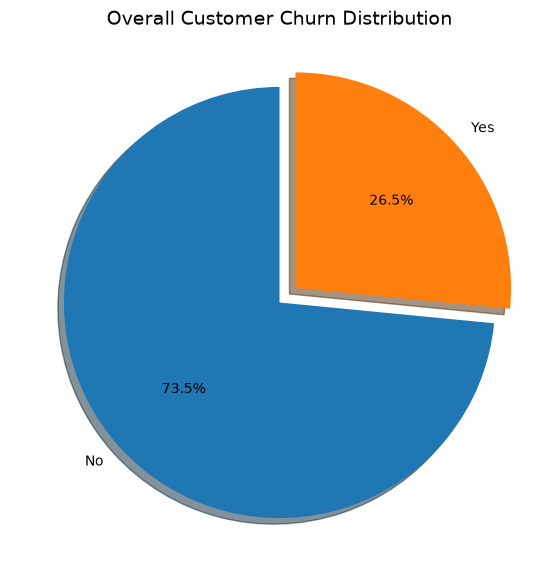

In [24]:
# Overall Customer Churn Distribution

churn_counts = df_clean['Churn'].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    churn_counts,
    labels=churn_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    explode=(0, 0.1),
    shadow=True
)

plt.title('Overall Customer Churn Distribution', fontsize=14)
plt.show()

In [25]:
# Churn Analysis by Gender

gender_churn = pd.crosstab(
    df_clean['gender'],
    df_clean['Churn']
)

gender_churn['Total Customers'] = gender_churn.sum(axis=1)

gender_churn['Churn Rate (%)'] = (
    gender_churn['Yes'] / gender_churn['Total Customers']
) * 100

gender_churn

Churn,No,Yes,Total Customers,Churn Rate (%)
gender,,,,
Female,2549,939,3488,26.920872
Male,2625,930,3555,26.160338


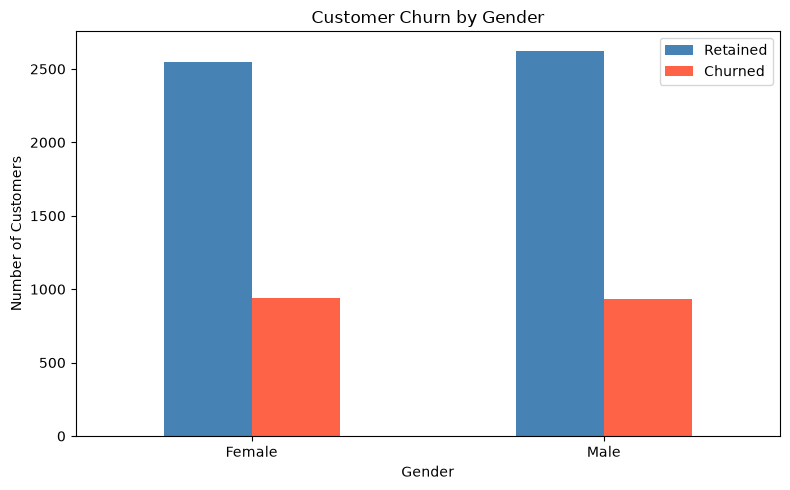

In [26]:
# Churn by Gender Visualization

gender_churn[['No', 'Yes']].plot(
    kind='bar',
    figsize=(8, 5),
    color=['steelblue', 'tomato']
)

plt.title('Customer Churn by Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Customers')
plt.xticks(rotation=0)
plt.legend(['Retained', 'Churned'])
plt.tight_layout()
plt.show()

In [27]:
# Churn Analysis by Senior Citizen Status

senior_churn = pd.crosstab(
    df_clean['SeniorCitizen'],
    df_clean['Churn']
)

senior_churn['Total Customers'] = senior_churn.sum(axis=1)

senior_churn['Churn Rate (%)'] = (
    senior_churn['Yes'] / senior_churn['Total Customers']
) * 100

senior_churn.index = ['Non-Senior Citizens', 'Senior Citizens']

senior_churn

Churn,No,Yes,Total Customers,Churn Rate (%)
Non-Senior Citizens,4508,1393,5901,23.606168
Senior Citizens,666,476,1142,41.681261


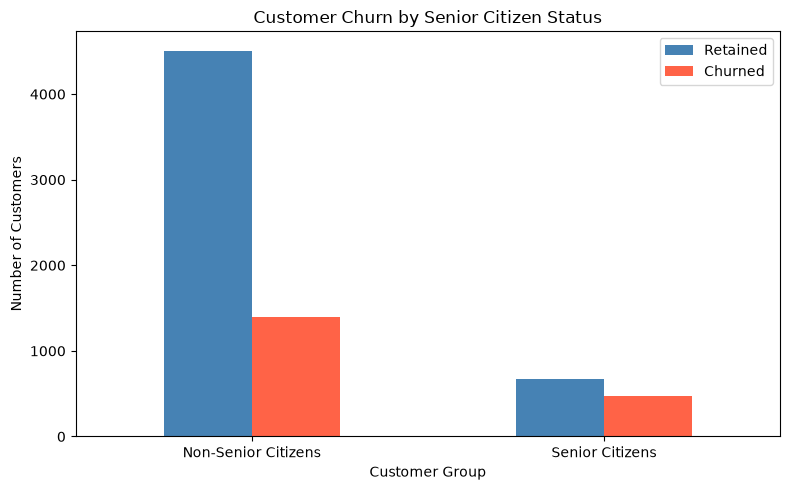

In [28]:
# Churn by Senior Citizen Status

senior_churn[['No', 'Yes']].plot(
    kind='bar',
    figsize=(8, 5),
    color=['steelblue', 'tomato']
)

plt.title('Customer Churn by Senior Citizen Status')
plt.xlabel('Customer Group')
plt.ylabel('Number of Customers')
plt.xticks(rotation=0)
plt.legend(['Retained', 'Churned'])
plt.tight_layout()
plt.show()

In [29]:
# Churn Analysis by Partner Status

partner_churn = pd.crosstab(
    df_clean['Partner'],
    df_clean['Churn']
)

partner_churn['Total Customers'] = partner_churn.sum(axis=1)

partner_churn['Churn Rate (%)'] = (
    partner_churn['Yes'] / partner_churn['Total Customers']
) * 100

partner_churn

Churn,No,Yes,Total Customers,Churn Rate (%)
Partner,,,,
No,2441,1200,3641,32.957979
Yes,2733,669,3402,19.664903


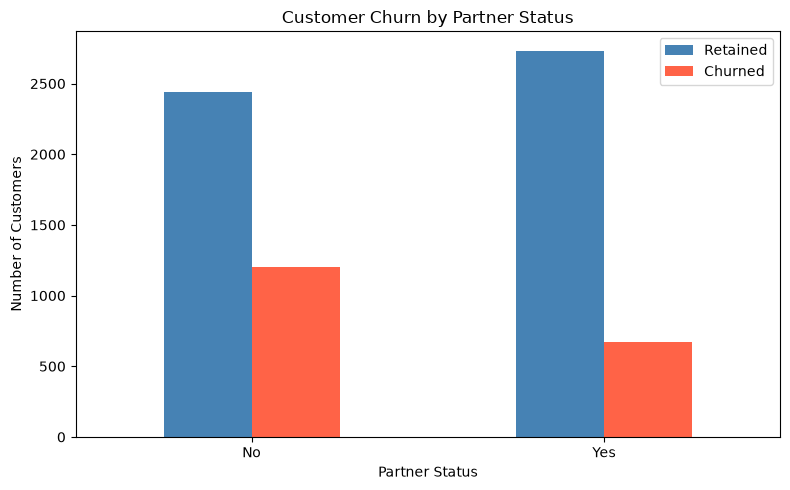

In [30]:
# Churn by Partner Status Visualization

partner_churn[['No', 'Yes']].plot(
    kind='bar',
    figsize=(8, 5),
    color=['steelblue', 'tomato']
)

plt.title('Customer Churn by Partner Status')
plt.xlabel('Partner Status')
plt.ylabel('Number of Customers')
plt.xticks(rotation=0)
plt.legend(['Retained', 'Churned'])
plt.tight_layout()
plt.show()

In [31]:
# Churn Analysis by Dependents

dependents_churn = pd.crosstab(
    df_clean['Dependents'],
    df_clean['Churn']
)

dependents_churn['Total Customers'] = dependents_churn.sum(axis=1)

dependents_churn['Churn Rate (%)'] = (
    dependents_churn['Yes'] / dependents_churn['Total Customers']
) * 100

dependents_churn

Churn,No,Yes,Total Customers,Churn Rate (%)
Dependents,,,,
No,3390,1543,4933,31.279140
Yes,1784,326,2110,15.450237


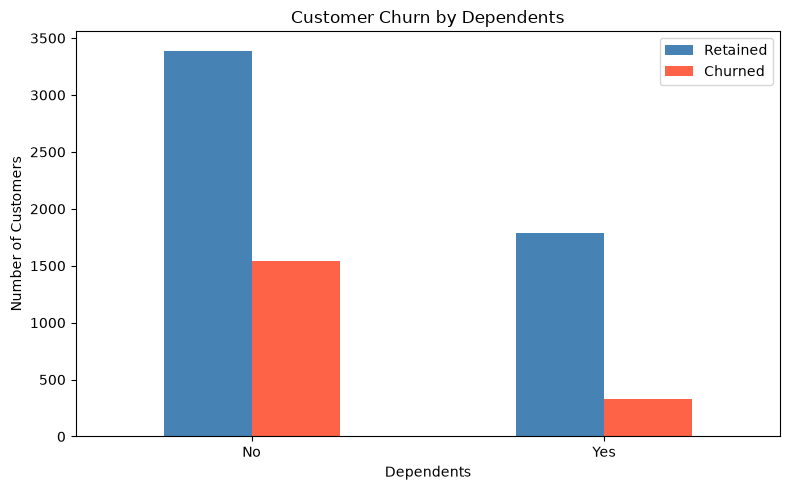

In [32]:
# Churn by Dependents Visualization

dependents_churn[['No', 'Yes']].plot(
    kind='bar',
    figsize=(8, 5),
    color=['steelblue', 'tomato']
)

plt.title('Customer Churn by Dependents')
plt.xlabel('Dependents')
plt.ylabel('Number of Customers')
plt.xticks(rotation=0)
plt.legend(['Retained', 'Churned'])
plt.tight_layout()
plt.show()

In [33]:
# Create Tenure Groups

bins = [0, 12, 24, 36, 48, 72]

labels = [
    '0-12 Months',
    '13-24 Months',
    '25-36 Months',
    '37-48 Months',
    '49-72 Months'
]

df_clean['TenureGroup'] = pd.cut(
    df_clean['tenure'],
    bins=bins,
    labels=labels,
    include_lowest=True
)

df_clean[['tenure', 'TenureGroup']].head(10)

,tenure,TenureGroup
0,1,0-12 Months
1,34,25-36 Months
2,2,0-12 Months
3,45,37-48 Months
4,2,0-12 Months
5,8,0-12 Months
6,22,13-24 Months
7,10,0-12 Months
8,28,25-36 Months
9,62,49-72 Months


In [34]:
# Churn Analysis by Tenure Group

tenure_churn = pd.crosstab(
    df_clean['TenureGroup'],
    df_clean['Churn']
)

tenure_churn['Total Customers'] = tenure_churn.sum(axis=1)

tenure_churn['Churn Rate (%)'] = (
    tenure_churn['Yes'] / tenure_churn['Total Customers']
) * 100

tenure_churn

Churn,No,Yes,Total Customers,Churn Rate (%)
TenureGroup,,,,
0-12 Months,1149,1037,2186,47.438243
13-24 Months,730,294,1024,28.710938
25-36 Months,652,180,832,21.634615
37-48 Months,617,145,762,19.028871
49-72 Months,2026,213,2239,9.513176


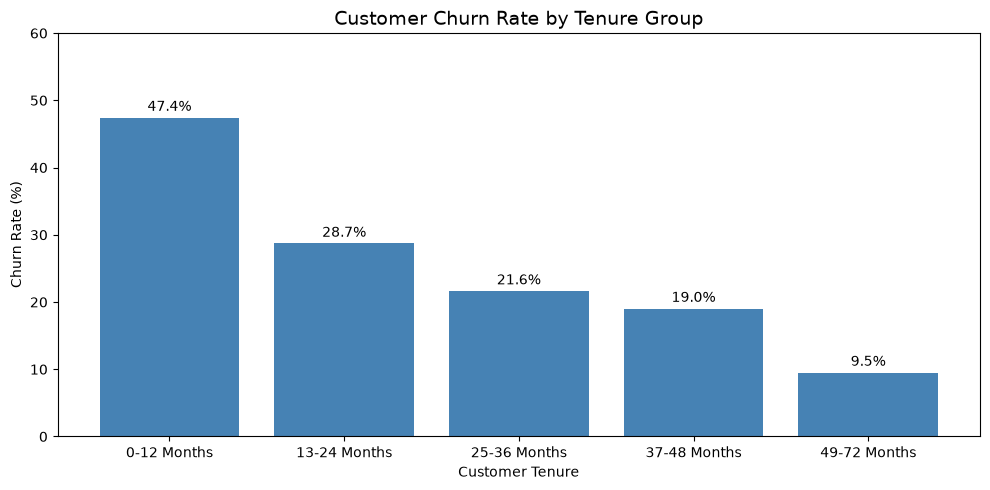

In [35]:
# Churn Rate by Tenure Group

plt.figure(figsize=(10, 5))

plt.bar(
    tenure_churn.index.astype(str),
    tenure_churn['Churn Rate (%)'],
    color='steelblue'
)

plt.title('Customer Churn Rate by Tenure Group', fontsize=14)
plt.xlabel('Customer Tenure')
plt.ylabel('Churn Rate (%)')

plt.ylim(0, 60)

for i, value in enumerate(tenure_churn['Churn Rate (%)']):
    plt.text(i, value + 1, f'{value:.1f}%', ha='center')

plt.tight_layout()
plt.show()

In [36]:
# Churn Analysis by Contract Type

contract_churn = pd.crosstab(
    df_clean['Contract'],
    df_clean['Churn']
)

contract_churn['Total Customers'] = contract_churn.sum(axis=1)

contract_churn['Churn Rate (%)'] = (
    contract_churn['Yes'] / contract_churn['Total Customers']
) * 100

contract_churn

Churn,No,Yes,Total Customers,Churn Rate (%)
Contract,,,,
Month-to-month,2220,1655,3875,42.709677
One year,1307,166,1473,11.269518
Two year,1647,48,1695,2.831858


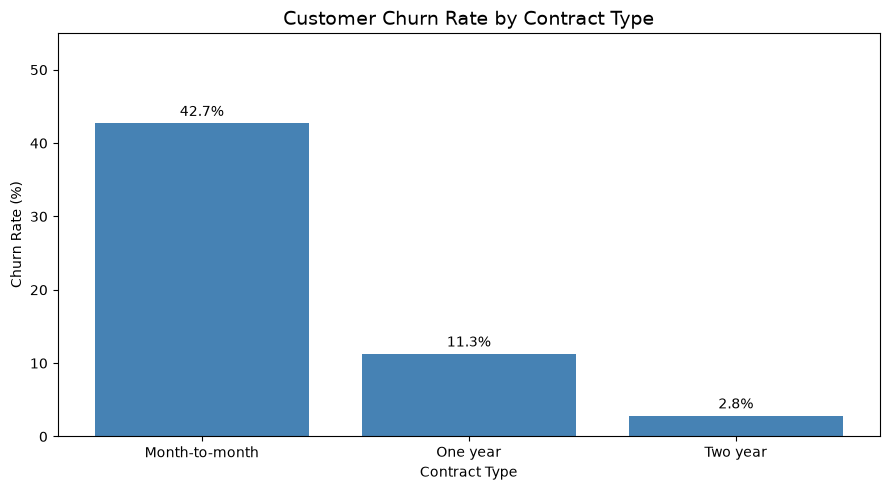

In [37]:
# Churn Rate by Contract Type

plt.figure(figsize=(9, 5))

plt.bar(
    contract_churn.index,
    contract_churn['Churn Rate (%)'],
    color='steelblue'
)

plt.title('Customer Churn Rate by Contract Type', fontsize=14)
plt.xlabel('Contract Type')
plt.ylabel('Churn Rate (%)')

plt.ylim(0, 55)

for i, value in enumerate(contract_churn['Churn Rate (%)']):
    plt.text(i, value + 1, f'{value:.1f}%', ha='center')

plt.tight_layout()
plt.show()

In [38]:
# Churn Analysis by Internet Service

internet_churn = pd.crosstab(
    df_clean['InternetService'],
    df_clean['Churn']
)

internet_churn['Total Customers'] = internet_churn.sum(axis=1)

internet_churn['Churn Rate (%)'] = (
    internet_churn['Yes'] / internet_churn['Total Customers']
) * 100

internet_churn

Churn,No,Yes,Total Customers,Churn Rate (%)
InternetService,,,,
DSL,1962,459,2421,18.959108
Fiber optic,1799,1297,3096,41.892765
No,1413,113,1526,7.404980


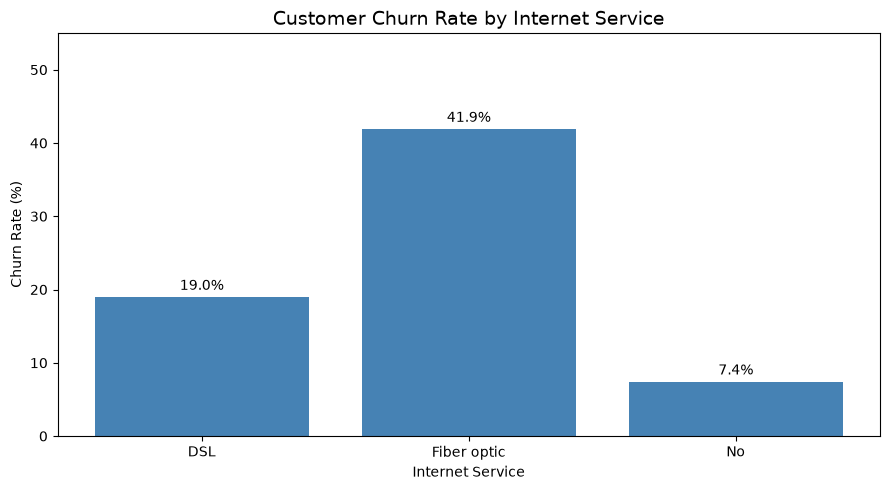

In [39]:
# Churn Rate by Internet Service

plt.figure(figsize=(9, 5))

plt.bar(
    internet_churn.index,
    internet_churn['Churn Rate (%)'],
    color='steelblue'
)

plt.title('Customer Churn Rate by Internet Service', fontsize=14)
plt.xlabel('Internet Service')
plt.ylabel('Churn Rate (%)')

plt.ylim(0, 55)

for i, value in enumerate(internet_churn['Churn Rate (%)']):
    plt.text(i, value + 1, f'{value:.1f}%', ha='center')

plt.tight_layout()
plt.show()

In [40]:
# Churn Analysis by Payment Method

payment_churn = pd.crosstab(
    df_clean['PaymentMethod'],
    df_clean['Churn']
)

payment_churn['Total Customers'] = payment_churn.sum(axis=1)

payment_churn['Churn Rate (%)'] = (
    payment_churn['Yes'] / payment_churn['Total Customers']
) * 100

payment_churn.sort_values(
    by='Churn Rate (%)',
    ascending=False
)

Churn,No,Yes,Total Customers,Churn Rate (%)
PaymentMethod,,,,
Electronic check,1294,1071,2365,45.285412
Mailed check,1304,308,1612,19.106700
Bank transfer (automatic),1286,258,1544,16.709845
Credit card (automatic),1290,232,1522,15.243101


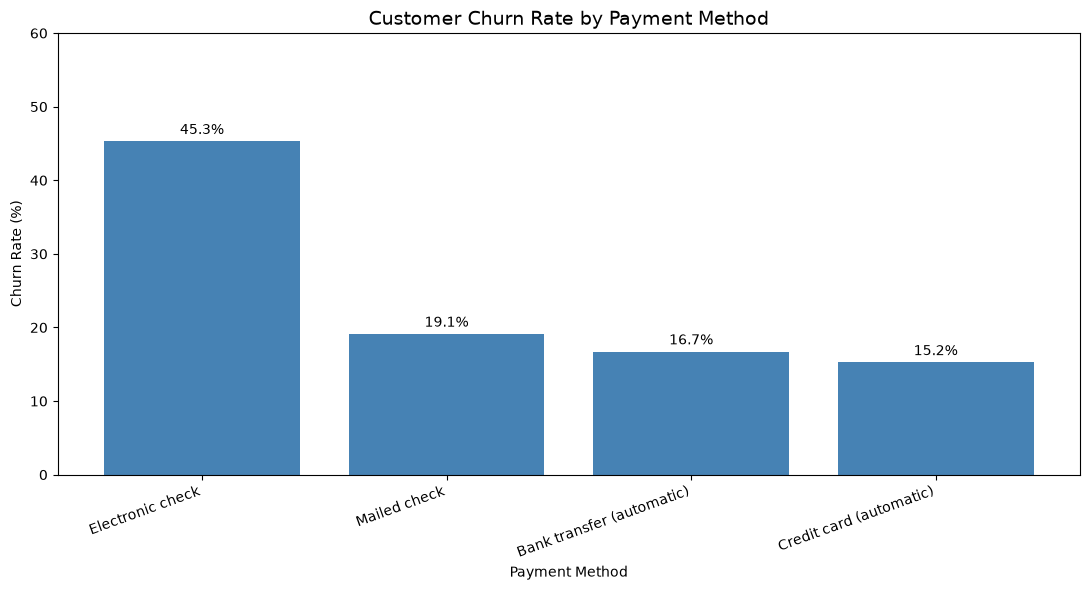

In [41]:
# Churn Rate by Payment Method

payment_sorted = payment_churn.sort_values(
    by='Churn Rate (%)',
    ascending=False
)

plt.figure(figsize=(11, 6))

plt.bar(
    payment_sorted.index,
    payment_sorted['Churn Rate (%)'],
    color='steelblue'
)

plt.title('Customer Churn Rate by Payment Method', fontsize=14)
plt.xlabel('Payment Method')
plt.ylabel('Churn Rate (%)')

plt.xticks(rotation=20, ha='right')
plt.ylim(0, 60)

for i, value in enumerate(payment_sorted['Churn Rate (%)']):
    plt.text(i, value + 1, f'{value:.1f}%', ha='center')

plt.tight_layout()
plt.show()

In [42]:
# Monthly Charges Analysis by Churn

monthly_charges_analysis = df_clean.groupby('Churn')['MonthlyCharges'].agg(
    ['count', 'mean', 'median', 'min', 'max']
)

monthly_charges_analysis

,count,mean,median,min,max
Churn,,,,,
No,5174,61.265124,64.425,18.25,118.75
Yes,1869,74.441332,79.650,18.85,118.35


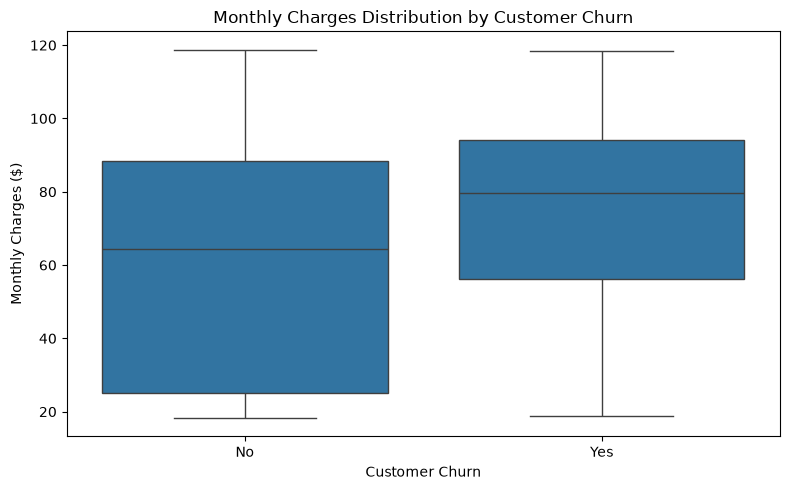

In [43]:
# Monthly Charges Distribution by Churn

plt.figure(figsize=(8, 5))

sns.boxplot(
    x='Churn',
    y='MonthlyCharges',
    data=df_clean
)

plt.title('Monthly Charges Distribution by Customer Churn')
plt.xlabel('Customer Churn')
plt.ylabel('Monthly Charges ($)')

plt.tight_layout()
plt.show()

In [44]:
# Total Charges Analysis by Churn

total_charges_analysis = df_clean.groupby('Churn')['TotalCharges'].agg(
    ['count', 'mean', 'median', 'min', 'max']
)

total_charges_analysis

,count,mean,median,min,max
Churn,,,,,
No,5174,2549.911442,1679.525,0.00,8672.45
Yes,1869,1531.796094,703.550,18.85,8684.80


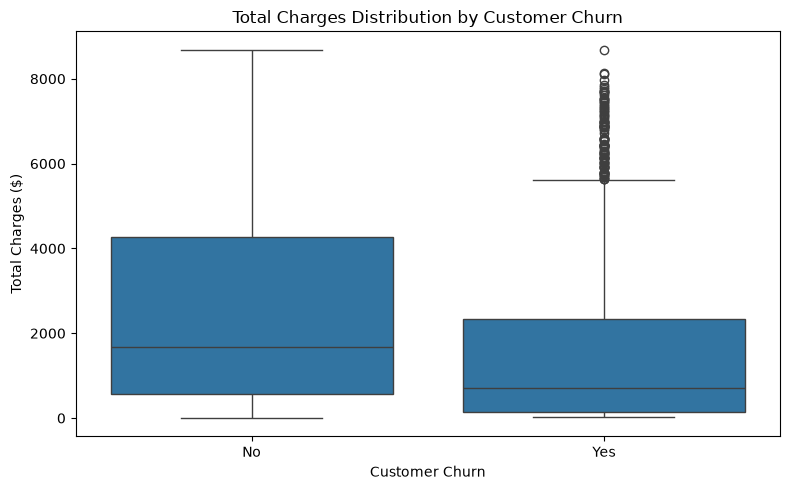

In [45]:
# Total Charges Distribution by Churn

plt.figure(figsize=(8, 5))

sns.boxplot(
    x='Churn',
    y='TotalCharges',
    data=df_clean
)

plt.title('Total Charges Distribution by Customer Churn')
plt.xlabel('Customer Churn')
plt.ylabel('Total Charges ($)')

plt.tight_layout()
plt.show()

In [46]:
# Customer Churn by Tech Support

tech_support_churn = pd.crosstab(
    df_clean['TechSupport'],
    df_clean['Churn']
)

tech_support_churn['Total Customers'] = tech_support_churn.sum(axis=1)

tech_support_churn['Churn Rate (%)'] = (
    tech_support_churn['Yes'] /
    tech_support_churn['Total Customers']
) * 100

tech_support_churn.sort_values(
    by='Churn Rate (%)',
    ascending=False
)

Churn,No,Yes,Total Customers,Churn Rate (%)
TechSupport,,,,
No,2027,1446,3473,41.635474
Yes,1734,310,2044,15.166341
No internet service,1413,113,1526,7.404980


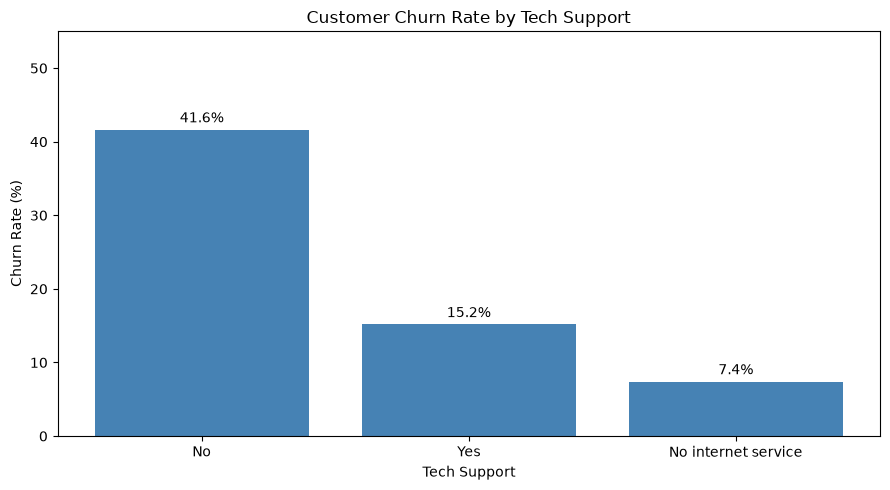

In [47]:
# Churn Rate by Tech Support

tech_support_sorted = tech_support_churn.sort_values(
    by='Churn Rate (%)',
    ascending=False
)

plt.figure(figsize=(9, 5))

plt.bar(
    tech_support_sorted.index,
    tech_support_sorted['Churn Rate (%)'],
    color='steelblue'
)

plt.title('Customer Churn Rate by Tech Support')
plt.xlabel('Tech Support')
plt.ylabel('Churn Rate (%)')
plt.ylim(0, 55)

for i, value in enumerate(tech_support_sorted['Churn Rate (%)']):
    plt.text(i, value + 1, f'{value:.1f}%', ha='center')

plt.tight_layout()
plt.show()

In [48]:
# Customer Churn by Online Security

online_security_churn = pd.crosstab(
    df_clean['OnlineSecurity'],
    df_clean['Churn']
)

online_security_churn['Total Customers'] = (
    online_security_churn.sum(axis=1)
)

online_security_churn['Churn Rate (%)'] = (
    online_security_churn['Yes'] /
    online_security_churn['Total Customers']
) * 100

online_security_churn.sort_values(
    by='Churn Rate (%)',
    ascending=False
)

Churn,No,Yes,Total Customers,Churn Rate (%)
OnlineSecurity,,,,
No,2037,1461,3498,41.766724
Yes,1724,295,2019,14.611194
No internet service,1413,113,1526,7.404980


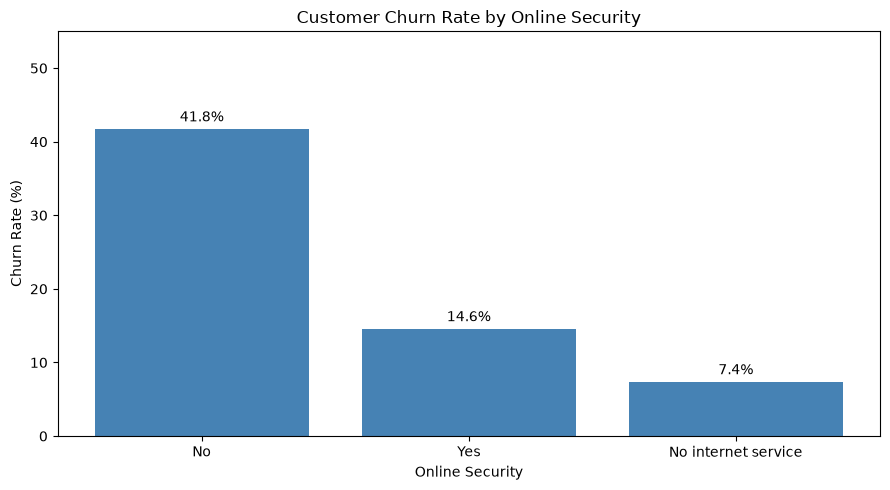

In [49]:
# Churn Rate by Online Security

security_sorted = online_security_churn.sort_values(
    by='Churn Rate (%)',
    ascending=False
)

plt.figure(figsize=(9, 5))

plt.bar(
    security_sorted.index,
    security_sorted['Churn Rate (%)'],
    color='steelblue'
)

plt.title('Customer Churn Rate by Online Security')
plt.xlabel('Online Security')
plt.ylabel('Churn Rate (%)')
plt.ylim(0, 55)

for i, value in enumerate(security_sorted['Churn Rate (%)']):
    plt.text(i, value + 1, f'{value:.1f}%', ha='center')

plt.tight_layout()
plt.show()

In [50]:
# Customer Churn by Online Backup

online_backup_churn = pd.crosstab(
    df_clean['OnlineBackup'],
    df_clean['Churn']
)

online_backup_churn['Total Customers'] = (
    online_backup_churn.sum(axis=1)
)

online_backup_churn['Churn Rate (%)'] = (
    online_backup_churn['Yes'] /
    online_backup_churn['Total Customers']
) * 100

online_backup_churn.sort_values(
    by='Churn Rate (%)',
    ascending=False
)

Churn,No,Yes,Total Customers,Churn Rate (%)
OnlineBackup,,,,
No,1855,1233,3088,39.928756
Yes,1906,523,2429,21.531494
No internet service,1413,113,1526,7.404980


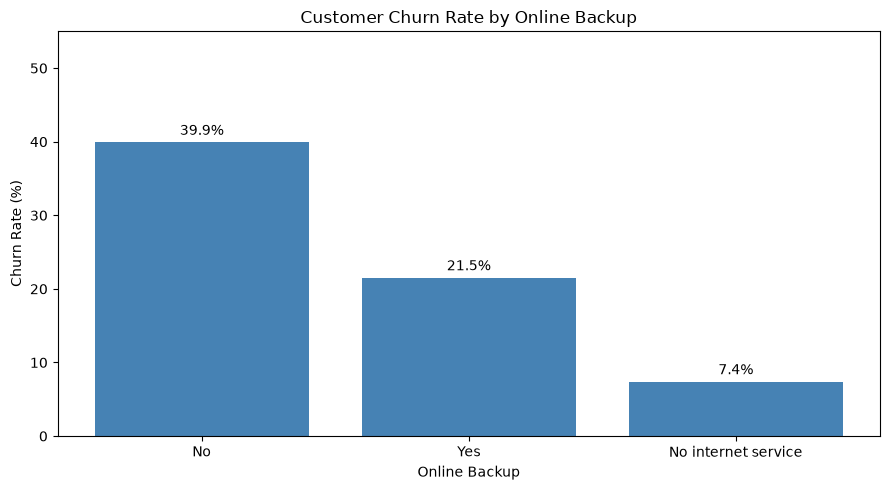

In [51]:
# Churn Rate by Online Backup

backup_sorted = online_backup_churn.sort_values(
    by='Churn Rate (%)',
    ascending=False
)

plt.figure(figsize=(9, 5))

plt.bar(
    backup_sorted.index,
    backup_sorted['Churn Rate (%)'],
    color='steelblue'
)

plt.title('Customer Churn Rate by Online Backup')
plt.xlabel('Online Backup')
plt.ylabel('Churn Rate (%)')
plt.ylim(0, 55)

for i, value in enumerate(backup_sorted['Churn Rate (%)']):
    plt.text(i, value + 1, f'{value:.1f}%', ha='center')

plt.tight_layout()
plt.show()

In [52]:
# Customer Churn by Device Protection

device_protection_churn = pd.crosstab(
    df_clean['DeviceProtection'],
    df_clean['Churn']
)

device_protection_churn['Total Customers'] = (
    device_protection_churn.sum(axis=1)
)

device_protection_churn['Churn Rate (%)'] = (
    device_protection_churn['Yes'] /
    device_protection_churn['Total Customers']
) * 100

device_protection_churn.sort_values(
    by='Churn Rate (%)',
    ascending=False
)

Churn,No,Yes,Total Customers,Churn Rate (%)
DeviceProtection,,,,
No,1884,1211,3095,39.127625
Yes,1877,545,2422,22.502064
No internet service,1413,113,1526,7.404980


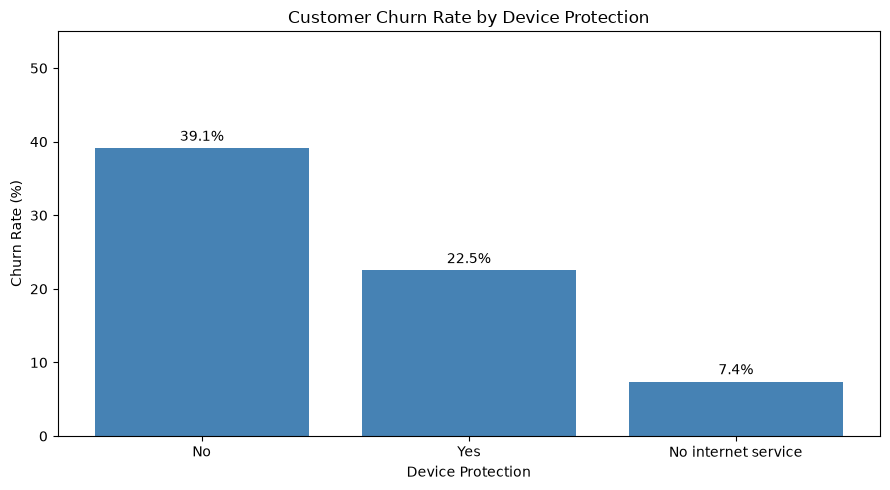

In [53]:
# Churn Rate by Device Protection

device_sorted = device_protection_churn.sort_values(
    by='Churn Rate (%)',
    ascending=False
)

plt.figure(figsize=(9, 5))

plt.bar(
    device_sorted.index,
    device_sorted['Churn Rate (%)'],
    color='steelblue'
)

plt.title('Customer Churn Rate by Device Protection')
plt.xlabel('Device Protection')
plt.ylabel('Churn Rate (%)')
plt.ylim(0, 55)

for i, value in enumerate(device_sorted['Churn Rate (%)']):
    plt.text(i, value + 1, f'{value:.1f}%', ha='center')

plt.tight_layout()
plt.show()

In [54]:
# Customer Churn by Streaming TV

streaming_tv_churn = pd.crosstab(
    df_clean['StreamingTV'],
    df_clean['Churn']
)

streaming_tv_churn['Total Customers'] = (
    streaming_tv_churn.sum(axis=1)
)

streaming_tv_churn['Churn Rate (%)'] = (
    streaming_tv_churn['Yes'] /
    streaming_tv_churn['Total Customers']
) * 100

streaming_tv_churn.sort_values(
    by='Churn Rate (%)',
    ascending=False
)

Churn,No,Yes,Total Customers,Churn Rate (%)
StreamingTV,,,,
No,1868,942,2810,33.523132
Yes,1893,814,2707,30.070188
No internet service,1413,113,1526,7.404980


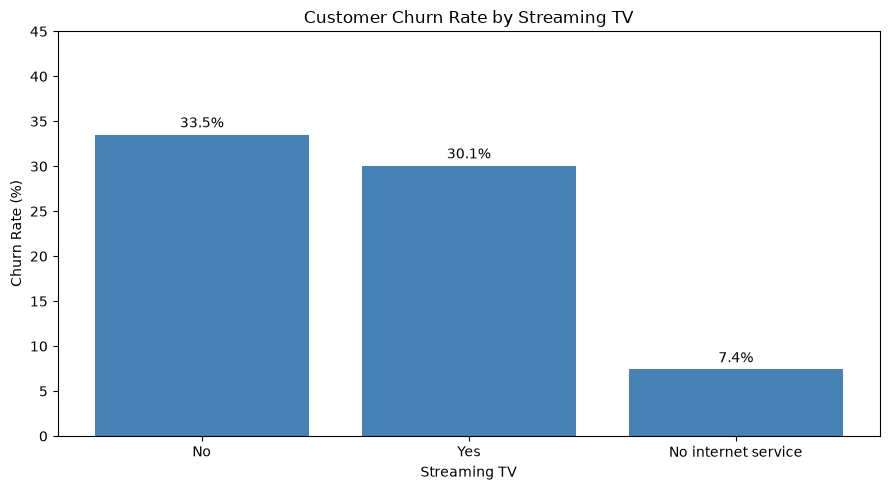

In [55]:
# Churn Rate by Streaming TV

streaming_tv_sorted = streaming_tv_churn.sort_values(
    by='Churn Rate (%)',
    ascending=False
)

plt.figure(figsize=(9, 5))

plt.bar(
    streaming_tv_sorted.index,
    streaming_tv_sorted['Churn Rate (%)'],
    color='steelblue'
)

plt.title('Customer Churn Rate by Streaming TV')
plt.xlabel('Streaming TV')
plt.ylabel('Churn Rate (%)')
plt.ylim(0, 45)

for i, value in enumerate(streaming_tv_sorted['Churn Rate (%)']):
    plt.text(i, value + 0.8, f'{value:.1f}%', ha='center')

plt.tight_layout()
plt.show()

In [56]:
# Customer Churn by Streaming Movies

streaming_movies_churn = pd.crosstab(
    df_clean['StreamingMovies'],
    df_clean['Churn']
)

streaming_movies_churn['Total Customers'] = (
    streaming_movies_churn.sum(axis=1)
)

streaming_movies_churn['Churn Rate (%)'] = (
    streaming_movies_churn['Yes'] /
    streaming_movies_churn['Total Customers']
) * 100

streaming_movies_churn.sort_values(
    by='Churn Rate (%)',
    ascending=False
)

Churn,No,Yes,Total Customers,Churn Rate (%)
StreamingMovies,,,,
No,1847,938,2785,33.680431
Yes,1914,818,2732,29.941435
No internet service,1413,113,1526,7.404980


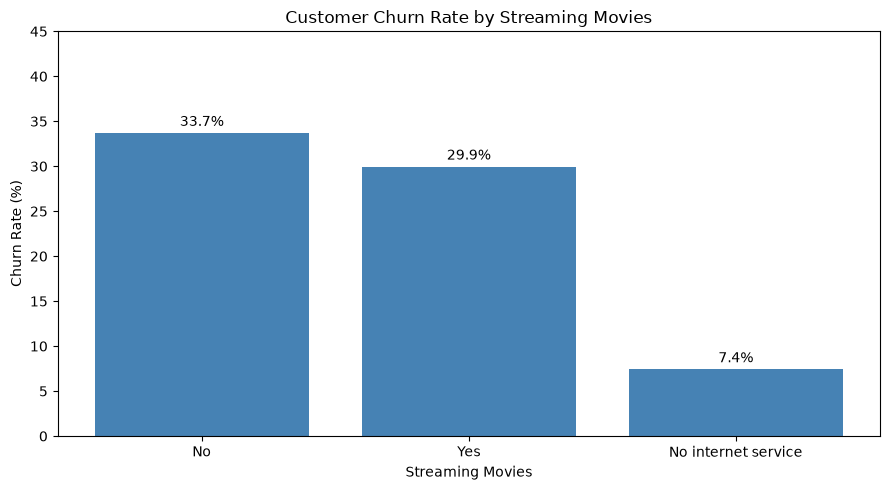

In [57]:
# Churn Rate by Streaming Movies

streaming_movies_sorted = streaming_movies_churn.sort_values(
    by='Churn Rate (%)',
    ascending=False
)

plt.figure(figsize=(9, 5))

plt.bar(
    streaming_movies_sorted.index,
    streaming_movies_sorted['Churn Rate (%)'],
    color='steelblue'
)

plt.title('Customer Churn Rate by Streaming Movies')
plt.xlabel('Streaming Movies')
plt.ylabel('Churn Rate (%)')
plt.ylim(0, 45)

for i, value in enumerate(streaming_movies_sorted['Churn Rate (%)']):
    plt.text(i, value + 0.8, f'{value:.1f}%', ha='center')

plt.tight_layout()
plt.show()

In [59]:
# Customer Churn by Paperless Billing

paperless_churn = pd.crosstab(
    df_clean['PaperlessBilling'],
    df_clean['Churn']
)

paperless_churn['Total Customers'] = (
    paperless_churn.sum(axis=1)
)

paperless_churn['Churn Rate (%)'] = (
    paperless_churn['Yes'] /
    paperless_churn['Total Customers']
) * 100

paperless_churn.sort_values(
    by='Churn Rate (%)',
    ascending=False
)

Churn,No,Yes,Total Customers,Churn Rate (%)
PaperlessBilling,,,,
Yes,2771,1400,4171,33.565092
No,2403,469,2872,16.330084


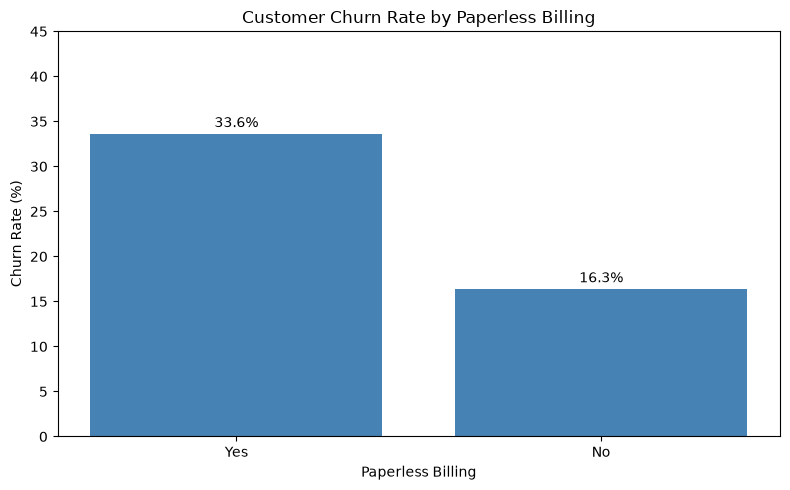

In [60]:
# Churn Rate by Paperless Billing

paperless_sorted = paperless_churn.sort_values(
    by='Churn Rate (%)',
    ascending=False
)

plt.figure(figsize=(8, 5))

plt.bar(
    paperless_sorted.index,
    paperless_sorted['Churn Rate (%)'],
    color='steelblue'
)

plt.title('Customer Churn Rate by Paperless Billing')
plt.xlabel('Paperless Billing')
plt.ylabel('Churn Rate (%)')
plt.ylim(0, 45)

for i, value in enumerate(paperless_sorted['Churn Rate (%)']):
    plt.text(i, value + 0.8, f'{value:.1f}%', ha='center')

plt.tight_layout()
plt.show()

In [61]:
# Customer Churn by Multiple Lines

multiple_lines_churn = pd.crosstab(
    df_clean['MultipleLines'],
    df_clean['Churn']
)

multiple_lines_churn['Total Customers'] = (
    multiple_lines_churn.sum(axis=1)
)

multiple_lines_churn['Churn Rate (%)'] = (
    multiple_lines_churn['Yes'] /
    multiple_lines_churn['Total Customers']
) * 100

multiple_lines_churn.sort_values(
    by='Churn Rate (%)',
    ascending=False
)

Churn,No,Yes,Total Customers,Churn Rate (%)
MultipleLines,,,,
Yes,2121,850,2971,28.609896
No,2541,849,3390,25.044248
No phone service,512,170,682,24.926686


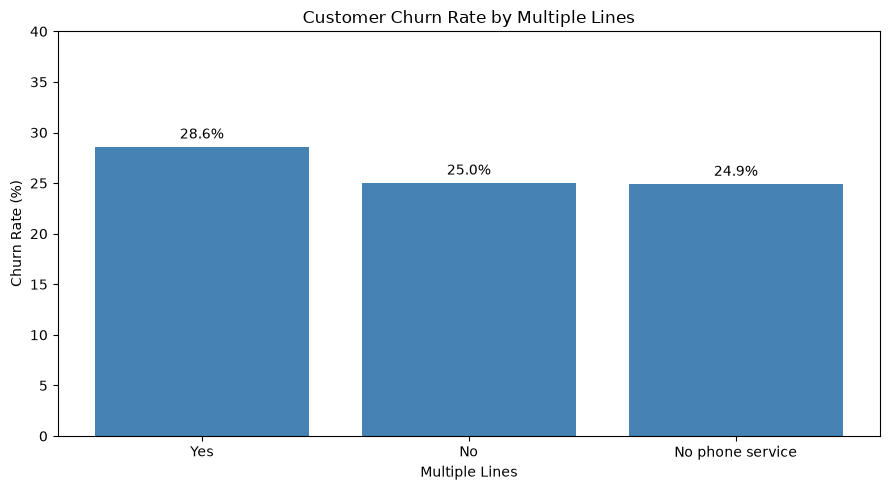

In [62]:
# Churn Rate by Multiple Lines

multiple_lines_sorted = multiple_lines_churn.sort_values(
    by='Churn Rate (%)',
    ascending=False
)

plt.figure(figsize=(9, 5))

plt.bar(
    multiple_lines_sorted.index,
    multiple_lines_sorted['Churn Rate (%)'],
    color='steelblue'
)

plt.title('Customer Churn Rate by Multiple Lines')
plt.xlabel('Multiple Lines')
plt.ylabel('Churn Rate (%)')
plt.ylim(0, 40)

for i, value in enumerate(multiple_lines_sorted['Churn Rate (%)']):
    plt.text(i, value + 0.8, f'{value:.1f}%', ha='center')

plt.tight_layout()
plt.show()

In [63]:
# Advanced Analysis: Contract Type + Internet Service

contract_internet_churn = pd.crosstab(
    [
        df_clean['Contract'],
        df_clean['InternetService']
    ],
    df_clean['Churn']
)

contract_internet_churn['Total Customers'] = (
    contract_internet_churn['No'] +
    contract_internet_churn['Yes']
)

contract_internet_churn['Churn Rate (%)'] = (
    contract_internet_churn['Yes'] /
    contract_internet_churn['Total Customers']
) * 100

contract_internet_churn.sort_values(
    by='Churn Rate (%)',
    ascending=False
)

Churn                            No   Yes  Total Customers  Churn Rate (%)
Contract       InternetService                                            
Month-to-month Fiber optic      966  1162             2128       54.605263
               DSL              829   394             1223       32.215863
One year       Fiber optic      435   104              539       19.294991
Month-to-month No               425    99              524       18.893130
One year       DSL              517    53              570        9.298246
Two year       Fiber optic      398    31              429        7.226107
One year       No               355     9              364        2.472527
Two year       DSL              616    12              628        1.910828
               No               633     5              638        0.783699

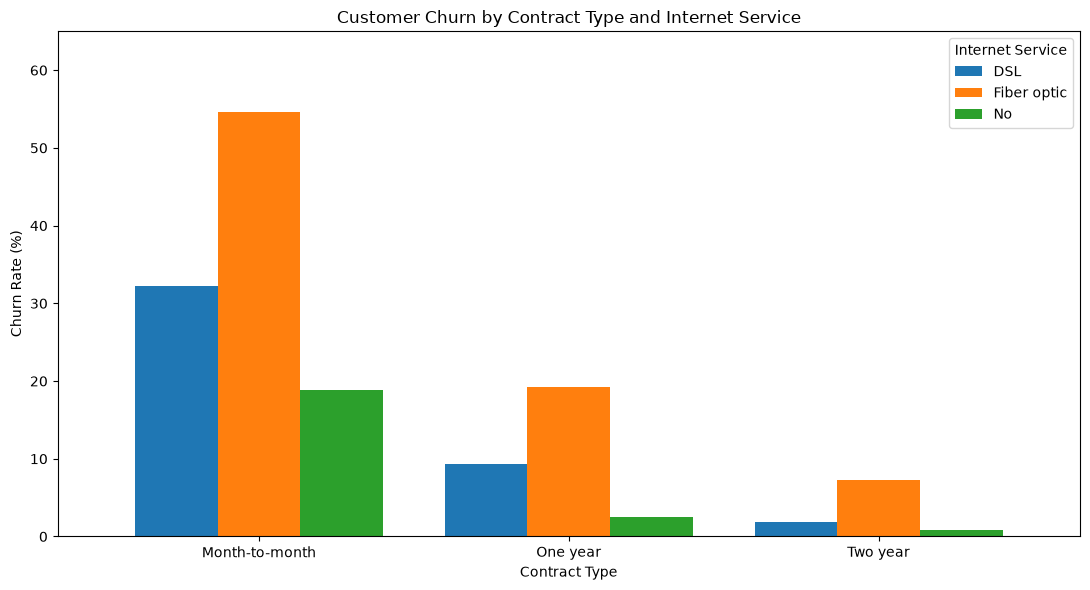

In [64]:
# Churn Rate by Contract Type and Internet Service

contract_internet_rates = contract_internet_churn['Churn Rate (%)'].unstack()

contract_internet_rates.plot(
    kind='bar',
    figsize=(11, 6),
    width=0.8
)

plt.title('Customer Churn by Contract Type and Internet Service')
plt.xlabel('Contract Type')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)
plt.ylim(0, 65)

plt.legend(title='Internet Service')
plt.tight_layout()
plt.show()

In [65]:
# Advanced Analysis: Tenure Group + Contract Type

tenure_contract_churn = pd.crosstab(
    [
        df_clean['TenureGroup'],
        df_clean['Contract']
    ],
    df_clean['Churn']
)

tenure_contract_churn['Total Customers'] = (
    tenure_contract_churn['No'] +
    tenure_contract_churn['Yes']
)

tenure_contract_churn['Churn Rate (%)'] = (
    tenure_contract_churn['Yes'] /
    tenure_contract_churn['Total Customers']
) * 100

tenure_contract_churn.sort_values(
    by='Churn Rate (%)',
    ascending=False
)

,Churn,No,Yes,Total Customers,Churn Rate (%)
TenureGroup,Contract,,,,
0-12 Months,Month-to-month,970,1024,1994,51.354062
13-24 Months,Month-to-month,459,278,737,37.720488
37-48 Months,Month-to-month,210,106,316,33.544304
25-36 Months,Month-to-month,328,158,486,32.510288
49-72 Months,Month-to-month,253,89,342,26.023392
37-48 Months,One year,233,35,268,13.059701
49-72 Months,One year,552,82,634,12.933754
0-12 Months,One year,111,13,124,10.483871
13-24 Months,One year,181,16,197,8.121827


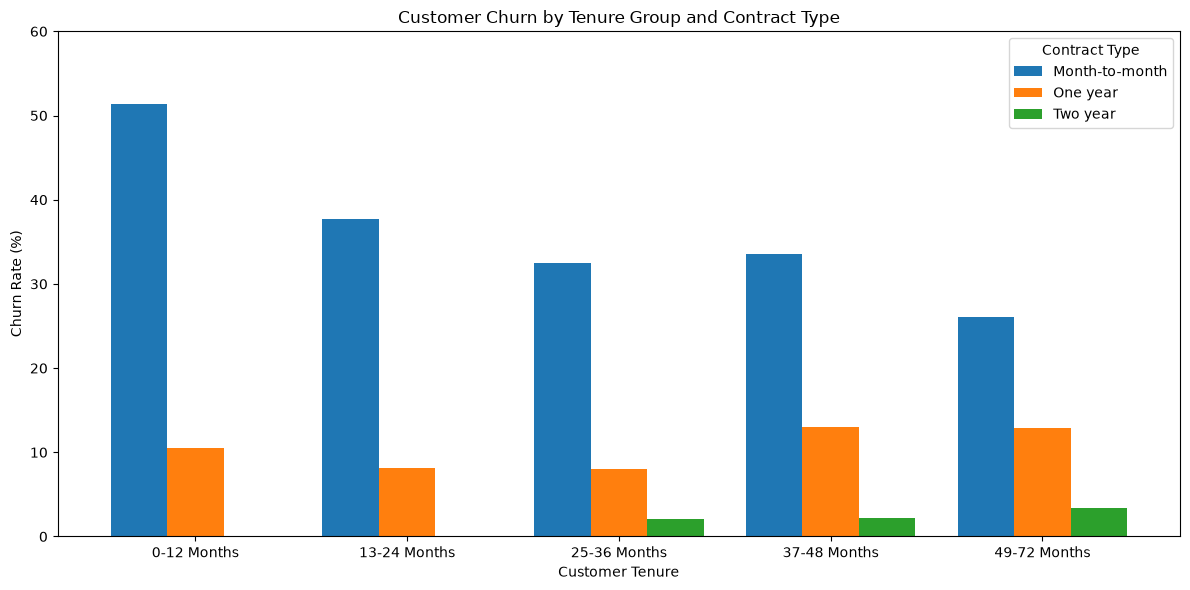

In [66]:
# Churn Rate by Tenure Group and Contract Type

tenure_contract_rates = tenure_contract_churn[
    'Churn Rate (%)'
].unstack()

tenure_contract_rates.plot(
    kind='bar',
    figsize=(12, 6),
    width=0.8
)

plt.title('Customer Churn by Tenure Group and Contract Type')
plt.xlabel('Customer Tenure')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)
plt.ylim(0, 60)

plt.legend(title='Contract Type')
plt.tight_layout()
plt.show()

In [67]:
# Create Monthly Charges Groups

bins = [0, 35, 70, float('inf')]

labels = ['Low Charges', 'Medium Charges', 'High Charges']

df_clean['MonthlyChargesGroup'] = pd.cut(
    df_clean['MonthlyCharges'],
    bins=bins,
    labels=labels,
    include_lowest=True
)

df_clean[['MonthlyCharges', 'MonthlyChargesGroup']].head(10)

,MonthlyCharges,MonthlyChargesGroup
0,29.85,Low Charges
1,56.95,Medium Charges
2,53.85,Medium Charges
3,42.30,Medium Charges
4,70.70,High Charges
5,99.65,High Charges
6,89.10,High Charges
7,29.75,Low Charges
8,104.80,High Charges
9,56.15,Medium Charges


In [68]:
# Churn by Monthly Charges and Contract Type

charges_contract_churn = pd.crosstab(
    [
        df_clean['MonthlyChargesGroup'],
        df_clean['Contract']
    ],
    df_clean['Churn']
)

charges_contract_churn['Total Customers'] = (
    charges_contract_churn['No'] +
    charges_contract_churn['Yes']
)

charges_contract_churn['Churn Rate (%)'] = (
    charges_contract_churn['Yes'] /
    charges_contract_churn['Total Customers']
) * 100

charges_contract_churn.sort_values(
    by='Churn Rate (%)',
    ascending=False
)

,Churn,No,Yes,Total Customers,Churn Rate (%)
MonthlyChargesGroup,Contract,,,,
High Charges,Month-to-month,992,1105,2097,52.694325
Medium Charges,Month-to-month,692,378,1070,35.327103
Low Charges,Month-to-month,536,172,708,24.293785
High Charges,One year,592,125,717,17.433752
Medium Charges,One year,342,29,371,7.816712
High Charges,Two year,732,37,769,4.811443
Low Charges,One year,373,12,385,3.116883
Medium Charges,Two year,278,6,284,2.112676
Low Charges,Two year,637,5,642,0.778816


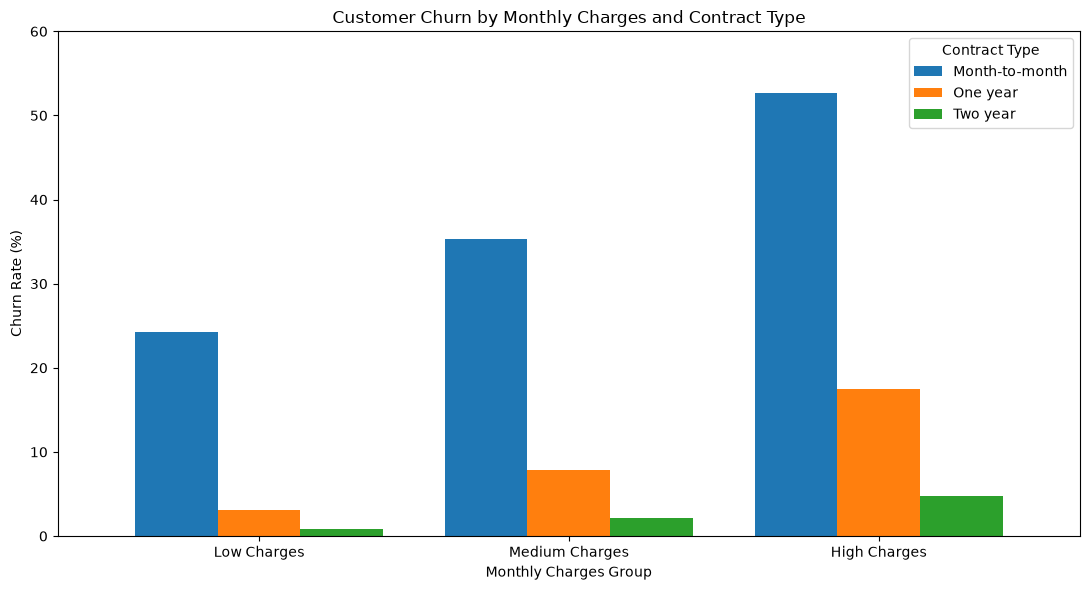

In [69]:
# Churn by Monthly Charges and Contract Type

charges_contract_rates = charges_contract_churn[
    'Churn Rate (%)'
].unstack()

charges_contract_rates.plot(
    kind='bar',
    figsize=(11, 6),
    width=0.8
)

plt.title('Customer Churn by Monthly Charges and Contract Type')
plt.xlabel('Monthly Charges Group')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)
plt.ylim(0, 60)

plt.legend(title='Contract Type')
plt.tight_layout()
plt.show()

In [70]:
# Create a numerical copy for correlation analysis

correlation_df = df_clean[
    ['tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']
].copy()

# Convert Churn into numerical values
correlation_df['Churn'] = correlation_df['Churn'].map({
    'No': 0,
    'Yes': 1
})

correlation_df.head()

,tenure,MonthlyCharges,TotalCharges,Churn
0,1,29.85,29.85,0
1,34,56.95,1889.50,0
2,2,53.85,108.15,1
3,45,42.30,1840.75,0
4,2,70.70,151.65,1


In [71]:
# Calculate correlation matrix

correlation_matrix = correlation_df.corr()

correlation_matrix

,tenure,MonthlyCharges,TotalCharges,Churn
tenure,1.000000,0.247900,0.826178,-0.352229
MonthlyCharges,0.247900,1.000000,0.651174,0.193356
TotalCharges,0.826178,0.651174,1.000000,-0.198324
Churn,-0.352229,0.193356,-0.198324,1.000000


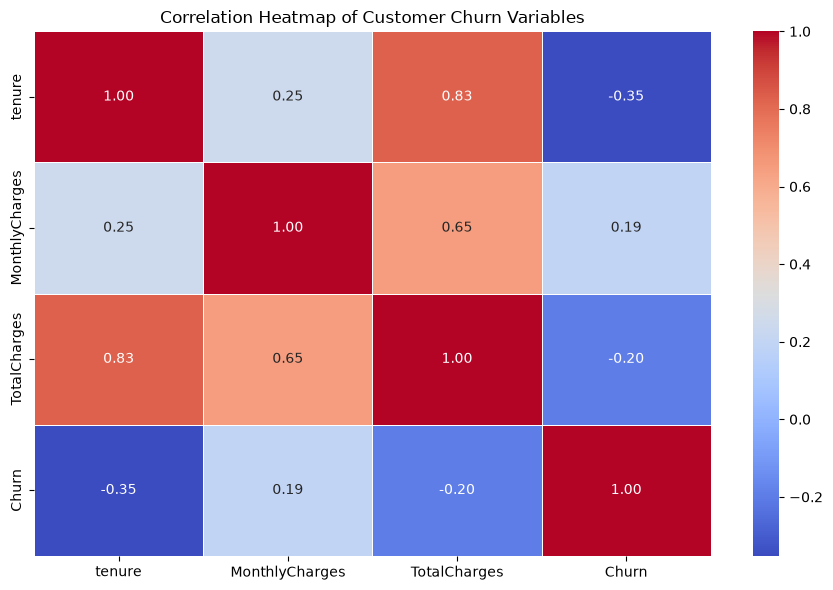

In [72]:
# Create correlation heatmap

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Customer Churn Variables')
plt.tight_layout()
plt.show()

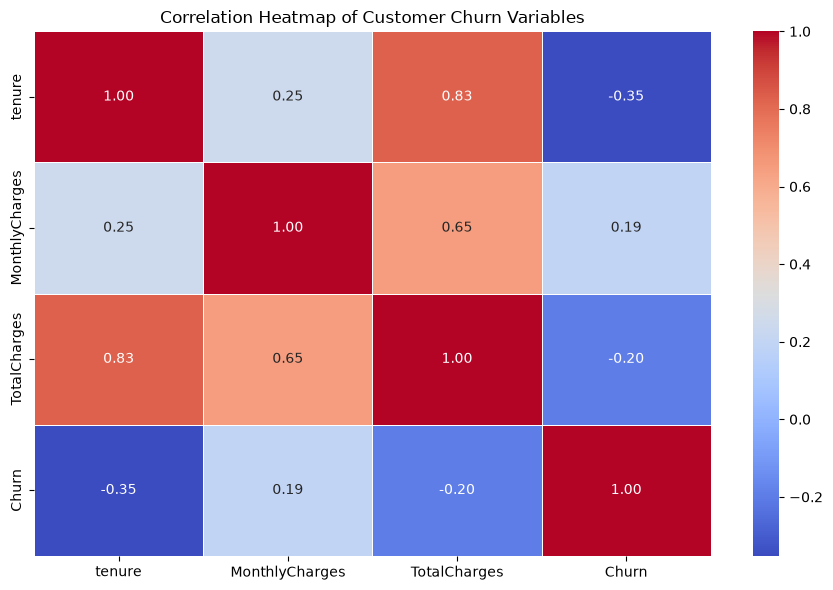

In [73]:
# Correlation Heatmap

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Customer Churn Variables')
plt.tight_layout()
plt.show()

In [74]:
# Export final cleaned dataset

df_clean.to_csv(
    'Customer_Churn_Final_Analysis.csv',
    index=False
)

print("Final analysis dataset exported successfully!")
print("Dataset shape:", df_clean.shape)

Final analysis dataset exported successfully!
Dataset shape: (7043, 23)
